# PDE vs. tree vs. Monte Carlo vs. quasi-Monte Carlo

All four methods price the same European call, for which Black-Scholes gives the exact answer, so the error is known exactly. The questions:

1. **Error vs. cost**: how many seconds does each method need to reach a given accuracy?
2. **Convergence orders**: PDE (Crank-Nicolson) is expected to be second order, MC $N^{-1/2}$, QMC close to $N^{-1}$, the binomial tree first order with an odd/even oscillation.
3. **Rannacher smoothing**: why the first two Crank-Nicolson steps are fully implicit, seen on delta and gamma.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import solve_banded

from pricing.black_scholes import black_scholes_price
from pricing.binomial import binomial_price
from pricing.greeks import analytical_greeks
from pricing.monte_carlo import mc_price
from pricing.pde import pde_price
from pricing.quasi_mc import qmc_price

In [2]:
# Market parameters (same as previous notebooks, for comparability)
S0 = 100.0
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
q = 0.02

bs = black_scholes_price(S0, K, T, r, sigma, "call", q)
print(f"Black-Scholes reference price: {bs:.8f}")


def timed(fn, repeats=1):
    t0 = time.perf_counter()
    for _ in range(repeats):
        out = fn()
    return out, (time.perf_counter() - t0) / repeats

Black-Scholes reference price: 9.22700551


## 1. Error vs. cost

For the deterministic methods (PDE, tree) one run per grid size. MC and QMC are random, so each point is the **root-mean-square error over 12 independent seeds**, which is the quantity that actually scales like $N^{-1/2}$; a single seed can be lucky.

In [3]:
rows = []

for n in [25, 50, 100, 200, 400, 800]:
    v, t = timed(lambda n=n: pde_price(S0, K, T, r, sigma, "call", q, n_space=n, n_time=n))
    rows.append({"method": "PDE (CN)", "size": n, "error": abs(v - bs), "seconds": t})

for n in [10, 20, 40, 80, 160, 320, 640, 1280, 2560]:
    v, t = timed(lambda n=n: binomial_price(S0, K, T, r, sigma, "call", q, n_steps=n))
    rows.append({"method": "Binomial (CRR)", "size": n, "error": abs(v - bs), "seconds": t})

n_seeds = 12
for N in [1_000, 4_000, 16_000, 64_000, 256_000, 1_024_000]:
    errs, ts = [], []
    for s in range(n_seeds):
        v, t = timed(lambda N=N, s=s: mc_price(S0, K, T, r, sigma, "call", q, n_paths=N, seed=100 + s).price)
        errs.append(v - bs); ts.append(t)
    rows.append({"method": "MC", "size": N, "error": np.sqrt(np.mean(np.square(errs))), "seconds": np.mean(ts)})

for m in [6, 8, 10, 12, 14, 16]:
    errs, ts = [], []
    for s in range(n_seeds):
        # 4 scrambles of 2**m points each: total 4 * 2**m evaluations
        v, t = timed(lambda m=m, s=s: qmc_price(S0, K, T, r, sigma, "call", q, log2_paths=m, n_replicates=4, seed=1000 + 10 * s).price)
        errs.append(v - bs); ts.append(t)
    rows.append({"method": "QMC (Sobol)", "size": 4 * 2**m, "error": np.sqrt(np.mean(np.square(errs))), "seconds": np.mean(ts)})

df = pd.DataFrame(rows)
df.pivot_table(index="size", columns="method", values="error").round(8)

method,Binomial (CRR),MC,PDE (CN),QMC (Sobol)
size,,,,
10,0.191680,NaN,NaN,NaN
20,0.096556,NaN,NaN,NaN
25,NaN,NaN,0.272935,NaN
40,0.048444,NaN,NaN,NaN
50,NaN,NaN,0.028712,NaN
80,0.024262,NaN,NaN,NaN
100,NaN,NaN,0.017174,NaN
160,0.012141,NaN,NaN,NaN
200,NaN,NaN,0.001024,NaN


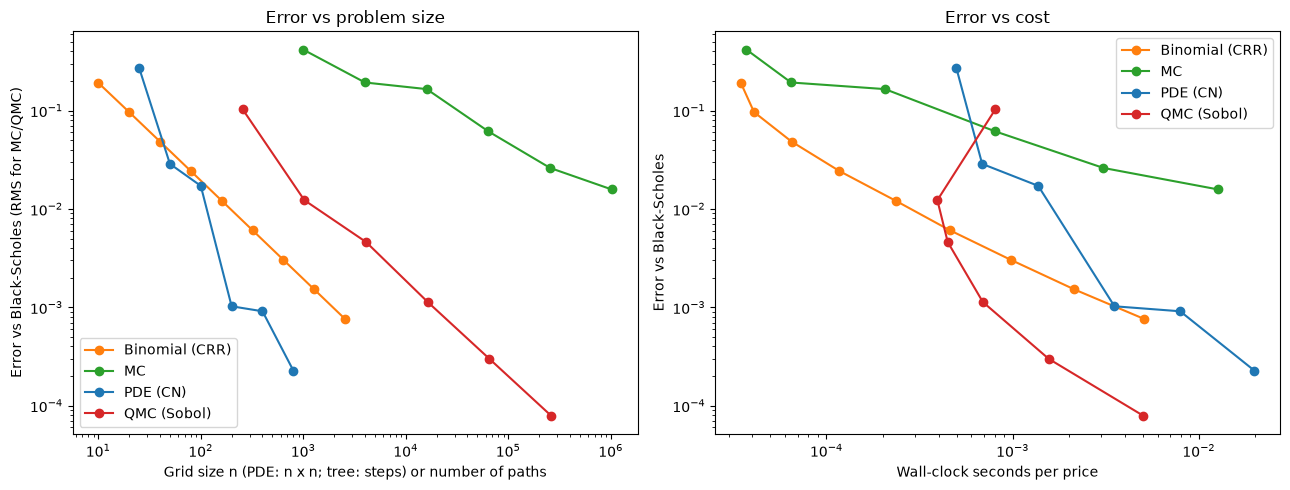

Binomial (CRR)   -1.00
MC               -0.49
PDE (CN)         -1.09
QMC (Sobol)      -0.96
Name: empirical slope, dtype: float64

In [4]:
colors = {"PDE (CN)": "C0", "Binomial (CRR)": "C1", "MC": "C2", "QMC (Sobol)": "C3"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for method, g in df.groupby("method"):
    axes[0].loglog(g["size"], g["error"], "o-", color=colors[method], label=method)
    axes[1].loglog(g["seconds"], g["error"], "o-", color=colors[method], label=method)
axes[0].set_xlabel("Grid size n (PDE: n x n; tree: steps) or number of paths")
axes[0].set_ylabel("Error vs Black-Scholes (RMS for MC/QMC)")
axes[0].set_title("Error vs problem size")
axes[1].set_xlabel("Wall-clock seconds per price")
axes[1].set_ylabel("Error vs Black-Scholes")
axes[1].set_title("Error vs cost")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

# Empirical convergence orders (slope of log error vs log size, on the finer half of each curve).
orders = {}
for method, g in df.groupby("method"):
    g = g.sort_values("size").iloc[len(g) // 2:]
    orders[method] = np.polyfit(np.log(g["size"]), np.log(g["error"]), 1)[0]
pd.Series(orders, name="empirical slope").round(2)

**Orders of convergence**

- **MC** has slope $-0.49$ and **QMC** $-0.96$ (against $N$, RMS over 12 seeds), as expected. At the biggest sizes QMC has an RMS error of $8\times10^{-5}$ with 262k points, where MC needs the 1M-path run to get to $1.6\times10^{-2}$: about 200 times larger.
- **Binomial** has slope $-1.00$: halving $\Delta t$ halves the error. The error is also signed and alternates with the parity of the number of steps (next section), so its absolute error at a given $n$ depends on luck.
- **PDE at a single strike** reads $-1.09$ over the table, which does not look like second order. The reason is visible in the raw numbers: the error is irregular (0.0287, 0.0172, 0.0010, 0.0009, 0.0002), because the kink falls at a different position relative to the grid nodes for each $n$. Averaging the squared error over 17 strikes (cell below) gives a slope of $-1.91$, so second order holds on average but a single price can look better or worse than that.

**Cost to reach a target error (K=100, one price)**: all methods take milliseconds here. For $10^{-3}$: PDE needs $400\times400$ (7.9 ms), the tree 2560 steps (4.8 ms), QMC 65,536 points (1.5 ms). Plain MC does not get to $10^{-2}$ within 1M paths. This is a favourable case for everything except MC: one dimension, a smooth-enough payoff and a known closed form. PDE and tree costs grow exponentially with the number of state variables, MC and QMC do not, which is why MC is still what is used for path-dependent or multi-asset products.

In [5]:
# Cheapest configuration of each method that reaches a target error (single price, K = 100).
rows_t = []
for target in (1e-2, 1e-3):
    for method, g in df.groupby("method"):
        ok = g[g["error"] <= target]
        rows_t.append({"target error": target, "method": method,
                       "size needed": ok["size"].min() if len(ok) else np.nan,
                       "seconds": ok["seconds"].min() if len(ok) else np.nan})
pd.DataFrame(rows_t).pivot(index="method", columns="target error", values=["size needed", "seconds"])

size needed           seconds          
target error         0.001   0.010     0.001     0.010
method                                                
Binomial (CRR)      2560.0   320.0  0.005105  0.000460
MC                     NaN     NaN       NaN       NaN
PDE (CN)             400.0   200.0  0.007941  0.003523
QMC (Sobol)        65536.0  4096.0  0.001563  0.000448

In [6]:
# The single-strike PDE error is irregular (the kink sits at a different place relative to the grid nodes for every n).
# Averaging the squared error over 17 strikes in [96, 104] smooths that out.
rows_p = []
test_strikes = np.linspace(96, 104, 17)
for n in [50, 100, 200, 400, 800]:
    e = [pde_price(S0, k_, T, r, sigma, "call", q, n_space=n, n_time=n) - black_scholes_price(S0, k_, T, r, sigma, "call", q) for k_ in test_strikes]
    rows_p.append({"n": n, "RMS error over strikes": np.sqrt(np.mean(np.square(e)))})
df_p = pd.DataFrame(rows_p)
slope_p = np.polyfit(np.log(df_p["n"]), np.log(df_p["RMS error over strikes"]), 1)[0]
print(df_p.to_string(index=False))
print(f"fitted slope over n = 50..800: {slope_p:.2f}")

  n  RMS error over strikes
 50                0.034299
100                0.013165
200                0.001764
400                0.000760
800                0.000187
fitted slope over n = 50..800: -1.91


## 2. Tree oscillation

The CRR price does not approach the exact value monotonically: with the strike at the money, the position of $K$ relative to the final nodes alternates with the parity of the number of steps.

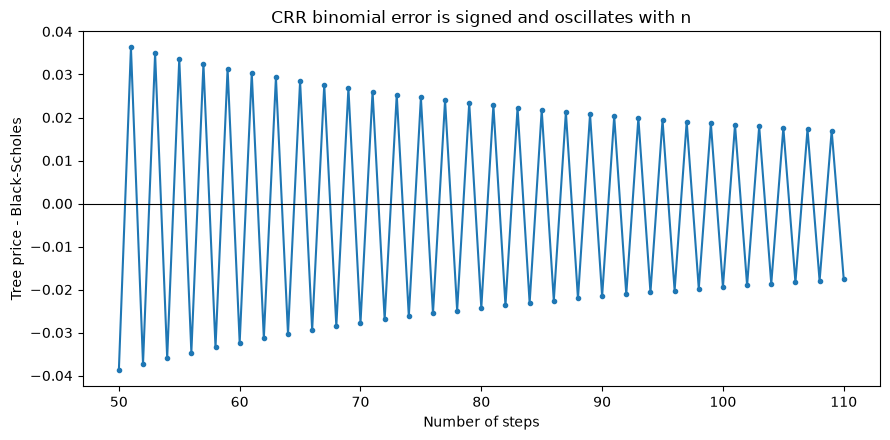

even n: mean error -0.02559; odd n: mean error +0.02430


In [7]:
ns = np.arange(50, 111)
tree_err = np.array([binomial_price(S0, K, T, r, sigma, "call", q, n_steps=int(n)) - bs for n in ns])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ns, tree_err, "o-", markersize=3)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xlabel("Number of steps")
ax.set_ylabel("Tree price - Black-Scholes")
ax.set_title("CRR binomial error is signed and oscillates with n")
fig.tight_layout()
plt.show()
print(f"even n: mean error {tree_err[ns % 2 == 0].mean():+.5f}; odd n: mean error {tree_err[ns % 2 == 1].mean():+.5f}")

Even $n$ gives a negative error (about $-0.026$ on average) and odd $n$ a positive one (about $+0.024$) with the strike at the money, so the tree converges to the exact value from alternating sides. A common remedy is averaging the prices for $n$ and $n+1$, or using Richardson extrapolation or a smoothed payoff at the last step.

## 3. Rannacher smoothing: delta and gamma

The payoff $\max(S-K,0)$ has a kink, so its second derivative is a Dirac delta. Crank-Nicolson is non-dissipative: it does not damp the high-frequency components that kink creates, and they show up as oscillations in the first steps. They are small in the price but amplified in delta and especially gamma. Replacing the first two steps by fully implicit steps (which damp high frequencies) fixes this at no extra cost.

`pricing.pde.pde_price` only returns the price at one spot, and always uses Rannacher. To look at delta and gamma I use a local copy of the same scheme that returns the whole grid and can switch the smoothing off.

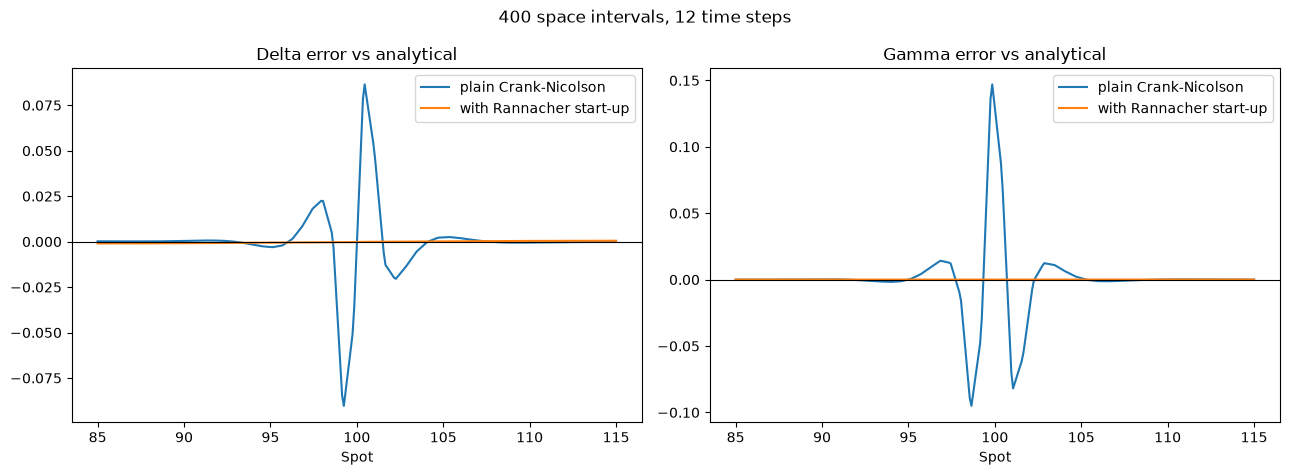

,max |delta err|,max |gamma err|,gamma err std (spot 85-115)
plain Crank-Nicolson,0.090319,0.146987,0.027695
with Rannacher start-up,0.000985,0.000158,0.000030


In [8]:
def cn_grid(n_space, n_time, rannacher, n_std=6.0):
    # Same scheme as pricing.pde for a European call; returns spots and values at tau = T.
    mu = r - q - 0.5 * sigma**2
    x = np.linspace(np.log(S0) + mu * T - n_std * sigma * np.sqrt(T), np.log(S0) + mu * T + n_std * sigma * np.sqrt(T), n_space + 1)
    dx, dt = x[1] - x[0], T / n_time
    spots = np.exp(x)
    v = np.maximum(spots - K, 0.0)
    lo = 0.5 * sigma**2 / dx**2 - mu / (2 * dx)
    di = -sigma**2 / dx**2 - r
    up = 0.5 * sigma**2 / dx**2 + mu / (2 * dx)
    m = n_space - 1
    for step in range(n_time):
        theta = 1.0 if (rannacher and step < 2) else 0.5
        tau = (step + 1) * dt
        ab = np.zeros((3, m))
        ab[0, 1:] = -theta * dt * up
        ab[1, :] = 1 - theta * dt * di
        ab[2, :-1] = -theta * dt * lo
        Lv = lo * v[:-2] + di * v[1:-1] + up * v[2:]
        rhs = v[1:-1] + (1 - theta) * dt * Lv
        hi_b = spots[-1] * np.exp(-q * tau) - K * np.exp(-r * tau)
        rhs[-1] += theta * dt * up * hi_b
        v[1:-1] = solve_banded((1, 1), ab, rhs)
        v[0], v[-1] = 0.0, hi_b
    return spots, v

def delta_gamma(spots, v):
    delta = np.gradient(v, spots)
    gamma = np.gradient(delta, spots)
    return delta, gamma

n_space, n_time = 400, 12   # few time steps makes the effect easy to see
S_plot = np.linspace(85, 115, 300)
g_exact = [analytical_greeks(s, K, T, r, sigma, "call", q) for s in S_plot]
delta_exact = np.array([g.delta for g in g_exact]); gamma_exact = np.array([g.gamma for g in g_exact])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
stats = {}
for label, ran in [("plain Crank-Nicolson", False), ("with Rannacher start-up", True)]:
    spots, v = cn_grid(n_space, n_time, ran)
    d, g = delta_gamma(spots, v)
    d_i, g_i = np.interp(S_plot, spots, d), np.interp(S_plot, spots, g)
    axes[0].plot(S_plot, d_i - delta_exact, label=label)
    axes[1].plot(S_plot, g_i - gamma_exact, label=label)
    stats[label] = {"max |delta err|": np.max(np.abs(d_i - delta_exact)), "max |gamma err|": np.max(np.abs(g_i - gamma_exact)),
                    "gamma err std (spot 85-115)": np.std(g_i - gamma_exact)}
axes[0].set_title("Delta error vs analytical"); axes[1].set_title("Gamma error vs analytical")
for ax in axes:
    ax.axhline(0, color="k", linewidth=0.8); ax.set_xlabel("Spot"); ax.legend()
fig.suptitle(f"{n_space} space intervals, {n_time} time steps")
fig.tight_layout()
plt.show()
pd.DataFrame(stats).T

**Rannacher**

With 12 time steps, plain Crank-Nicolson gives a maximum delta error of 0.090 and a maximum gamma error of 0.147 in the region $S\in[85,115]$, with the error concentrated around the strike. With the two implicit start-up steps the same grid gives 0.00099 and 0.00016: about 90 times smaller for delta and 900 times for gamma. Gamma is the sensitive quantity because it is the second derivative of a solution that carries the oscillation. The point for a Greeks engine: a PDE price that matches the benchmark can still produce unusable gamma if the start-up is not handled.